# 05. Train và đánh giá mô hình theo chuẩn LOSO

- Đánh giá kiểm thử chéo 15 người (**Leave-One-Subject-Out - LOSO**) để kiểm tra độ khái quát hóa trên người chưa từng thấy.
- 10 model, 6 thuật toán ML
- Dữ liệu đánh giá được sinh bởi script `scripts/train_wesad_baseline.py`.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_colwidth', None)
here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p / 'ai/requirements.txt').is_file() and (p / 'backend').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Vui lòng mở notebook trong repository ASD-EASE')
sys.path.insert(0, str(ROOT / 'ai'))

MODEL_DIR = ROOT / 'ai/models/wesad-baseline-v1'
rep = json.loads((MODEL_DIR / 'report.json').read_text(encoding='utf-8'))
three_rep = json.loads((MODEL_DIR / 'three_steps_report.json').read_text(encoding='utf-8')) if (MODEL_DIR / 'three_steps_report.json').is_file() else None
print(f'Báo cáo LOSO hoàn tất: {rep["status"]}, Tổng cửa sổ: {rep["total_windows"]}, Số đối tượng: {rep["total_subjects"]}')

Báo cáo LOSO hoàn tất: COMPLETE, Tổng cửa sổ: 3040, Số đối tượng: 15


## 1. So sánh hiệu năng các model

- So sánh Accuracy, Macro F1 và Stress F1 qua kiểm thử LOSO 15 fold.
- **Logistic Regression** đạt hiệu năng ấn tượng nhất: **Accuracy 89,74%**, **Macro F1 87,95%**, **Stress F1 83,30%**.

,Mô hình,Accuracy (%),Macro F1 (%),Stress F1 (%),Độ trễ (ms/mẫu),Thông lượng (PPS)
Hạng,,,,,,
1,"LogisticRegression (C=10.0, Tuned)",90.690789,88.989419,84.661247,0.069639,14360
2,LogisticRegression (C=1.0),89.736842,87.945119,83.297645,0.076261,13113
3,"SVM (Linear, C=1.0)",89.802632,87.905519,83.115468,0.207359,4823
4,"k-NN (k=7, distance weights)",89.210526,86.540473,80.545670,1.022681,978
5,MLP Neural Net (64x32),88.453947,86.145071,80.489161,0.080444,12431
6,"SVM (RBF, C=10.0, gamma='scale')",88.190789,85.717754,79.774648,0.235240,4251
7,"RandomForest (Tuned: 200 trees, depth=15)",84.013158,81.210999,73.954984,33.562872,30
8,"RandomForest (Default: 100 trees, depth=10)",84.078947,81.220686,73.894283,3.347740,299
9,"HistGradientBoosting (Tuned: lr=0.05, max_iter=150)",80.921053,78.211698,70.528455,3.033678,330


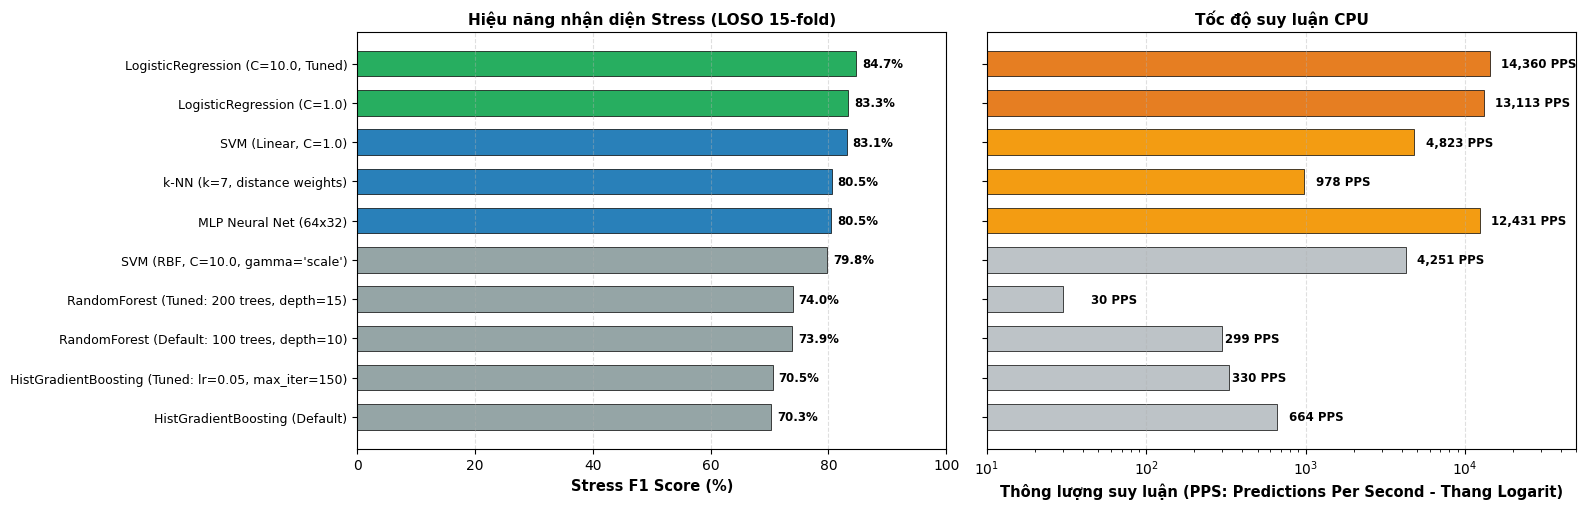

In [2]:
# 1. Bảng đối sánh các mô hình Machine Learning qua LOSO 15-fold (kèm độ trễ ms và thông lượng PPS)
if three_rep and 'models_benchmark' in three_rep:
    df_bench = pd.DataFrame(three_rep['models_benchmark'])
    df_bench['Throughput_pps'] = (1000.0 / df_bench['Latency_ms']).round(0).astype(int)
    df_bench = df_bench.rename(columns={
        'Model': 'Mô hình',
        'Acc_36': 'Accuracy (%)',
        'MacroF1_36': 'Macro F1 (%)',
        'StressF1_36': 'Stress F1 (%)',
        'Latency_ms': 'Độ trễ (ms/mẫu)',
        'Throughput_pps': 'Thông lượng (PPS)'
    })
    display_cols = ['Mô hình', 'Accuracy (%)', 'Macro F1 (%)', 'Stress F1 (%)', 'Độ trễ (ms/mẫu)', 'Thông lượng (PPS)']
    df_models = df_bench[display_cols].sort_values(by='Stress F1 (%)', ascending=False).reset_index(drop=True)
    df_models.index = df_models.index + 1
    df_models.index.name = 'Hạng'
else:
    model_keys = [
        ('RandomForest_ACC_only', 'Random Forest (Chỉ ACC)'),
        ('RandomForest_EDA_only', 'Random Forest (Chỉ EDA)'),
        ('RandomForest_EDA_and_ACC', 'Random Forest (EDA + ACC)'),
        ('RandomForest_Full_Multimodal', 'Random Forest (EDA + ACC + HR)'),
        ('HistGradientBoosting_Full_Multimodal', 'HistGradientBoosting (EDA + ACC + HR)'),
        ('LogisticRegression_Full_Multimodal', 'Logistic Regression (EDA + ACC + HR)')
    ]
    summary_rows = []
    for key, name in model_keys:
        if key in rep['models']:
            ov = rep['models'][key]['overall']
            summary_rows.append({
                'Mô hình': name,
                'Accuracy (%)': round(ov['accuracy'] * 100, 2),
                'Macro F1 (%)': round(ov['f1_macro'] * 100, 2),
                'Stress F1 (%)': round(ov['f1_stress'] * 100, 2)
            })
    df_models = pd.DataFrame(summary_rows)

display(df_models)

# 2. Vẽ biểu đồ đối sánh Stress F1 (%) và Thông lượng suy luận PPS (Predictions Per Second)
if 'Thông lượng (PPS)' in df_models.columns:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.2))
    
    # Stress F1 (%)
    y_pos = range(len(df_models))
    colors_f1 = ['#27AE60' if i < 2 else ('#2980B9' if i < 5 else '#95A5A6') for i in range(len(df_models))]
    bars1 = ax1.barh(y_pos, df_models['Stress F1 (%)'], color=colors_f1, height=0.65, edgecolor='black', linewidth=0.5)
    ax1.set_yticks(y_pos)
    ax1.set_yticklabels(df_models['Mô hình'], fontsize=9)
    ax1.invert_yaxis()
    for bar in bars1:
        w = bar.get_width()
        ax1.text(w + 1, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va='center', fontweight='bold', fontsize=8.5)
    ax1.set_xlim(0, 100)
    ax1.set_xlabel('Stress F1 Score (%)', fontsize=10.5, fontweight='bold')
    ax1.set_title('Hiệu năng nhận diện Stress (LOSO 15-fold)', fontsize=11, fontweight='bold')
    ax1.grid(axis='x', linestyle='--', alpha=0.4)
    
    # Thông lượng PPS
    colors_pps = ['#E67E22' if i < 2 else ('#F39C12' if i < 5 else '#BDC3C7') for i in range(len(df_models))]
    bars2 = ax2.barh(y_pos, df_models['Thông lượng (PPS)'], color=colors_pps, height=0.65, edgecolor='black', linewidth=0.5)
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels([])
    ax2.invert_yaxis()
    for bar in bars2:
        w = bar.get_width()
        ax2.text(w * 1.18 if w > 500 else w + 15, bar.get_y() + bar.get_height()/2, 
                 f"{int(w):,} PPS", va='center', fontsize=8.5, fontweight='bold')
    ax2.set_xscale('log')
    ax2.set_xlim(10, 50000)
    ax2.set_xlabel('Thông lượng suy luận (PPS: Predictions Per Second - Thang Logarit)', fontsize=10.5, fontweight='bold')
    ax2.set_title('Tốc độ suy luận CPU', fontsize=11, fontweight='bold')
    ax2.grid(axis='x', linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()
else:
    plt.figure(figsize=(9, 4.5))
    bars = plt.barh(df_models['Mô hình'], df_models['Stress F1 (%)'], color=['#95A5A6', '#E67E22', '#BDC3C7', '#3498DB', '#2980B9', '#27AE60'], height=0.6)
    plt.xlabel('Stress F1 Score (%)', fontsize=11)
    plt.title('Hiệu năng nhận diện Stress của các mô hình (LOSO 15-fold)', fontsize=12, pad=12)
    for bar in bars:
        w = bar.get_width()
        plt.text(w + 1, bar.get_y() + bar.get_height()/2.0, f'{w:.1f}%', va='center', fontweight='bold', fontsize=10)
    plt.xlim(0, 100)
    plt.grid(axis='x', linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

## 2. Phân tích tác động của từng nhóm feature (Ablation Study)

- Đo lường mức cải thiện khi lần lượt bổ sung các nhóm cảm biến vào mô hình Random Forest.
- Bổ sung HR giúp **Stress F1 tăng từ 62,97% lên 73,89%** (+10,92%).

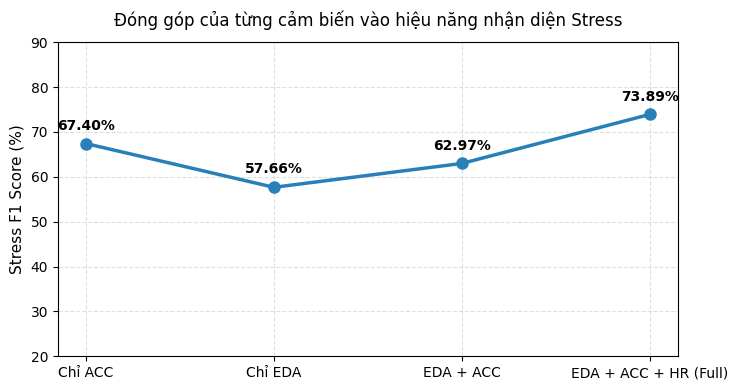

In [3]:
ablation_names = ['Chỉ ACC', 'Chỉ EDA', 'EDA + ACC', 'EDA + ACC + HR (Full)']
f1_scores = [
    rep['models']['RandomForest_ACC_only']['overall']['f1_stress'] * 100,
    rep['models']['RandomForest_EDA_only']['overall']['f1_stress'] * 100,
    rep['models']['RandomForest_EDA_and_ACC']['overall']['f1_stress'] * 100,
    rep['models']['RandomForest_Full_Multimodal']['overall']['f1_stress'] * 100
]

plt.figure(figsize=(7.5, 4))
plt.plot(ablation_names, f1_scores, marker='o', lw=2.5, color='#2980B9', markersize=8)
for x, y in zip(ablation_names, f1_scores):
    plt.annotate(f'{y:.2f}%', (x, y), textcoords='offset points', xytext=(0, 10), ha='center', fontweight='bold')
plt.ylabel('Stress F1 Score (%)', fontsize=11)
plt.ylim(20, 90)
plt.title('Đóng góp của từng cảm biến vào hiệu năng nhận diện Stress', fontsize=12, pad=12)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

## 3. Mô hình đa biến (Permutation Feature Importance)

Được đo lường bằng cách xáo trộn ngẫu nhiên các hàng của 1 đặc trưng (cột) trên tập kiểm thử chưa từng thấy trong kiểm thử chéo 15 người (LOSO 15-Fold) và ghi nhận mức độ sụt giảm điểm Macro F1:

$$\Delta F_1 = F_{1,\text{baseline}} - F_{1,\text{permuted}}$$

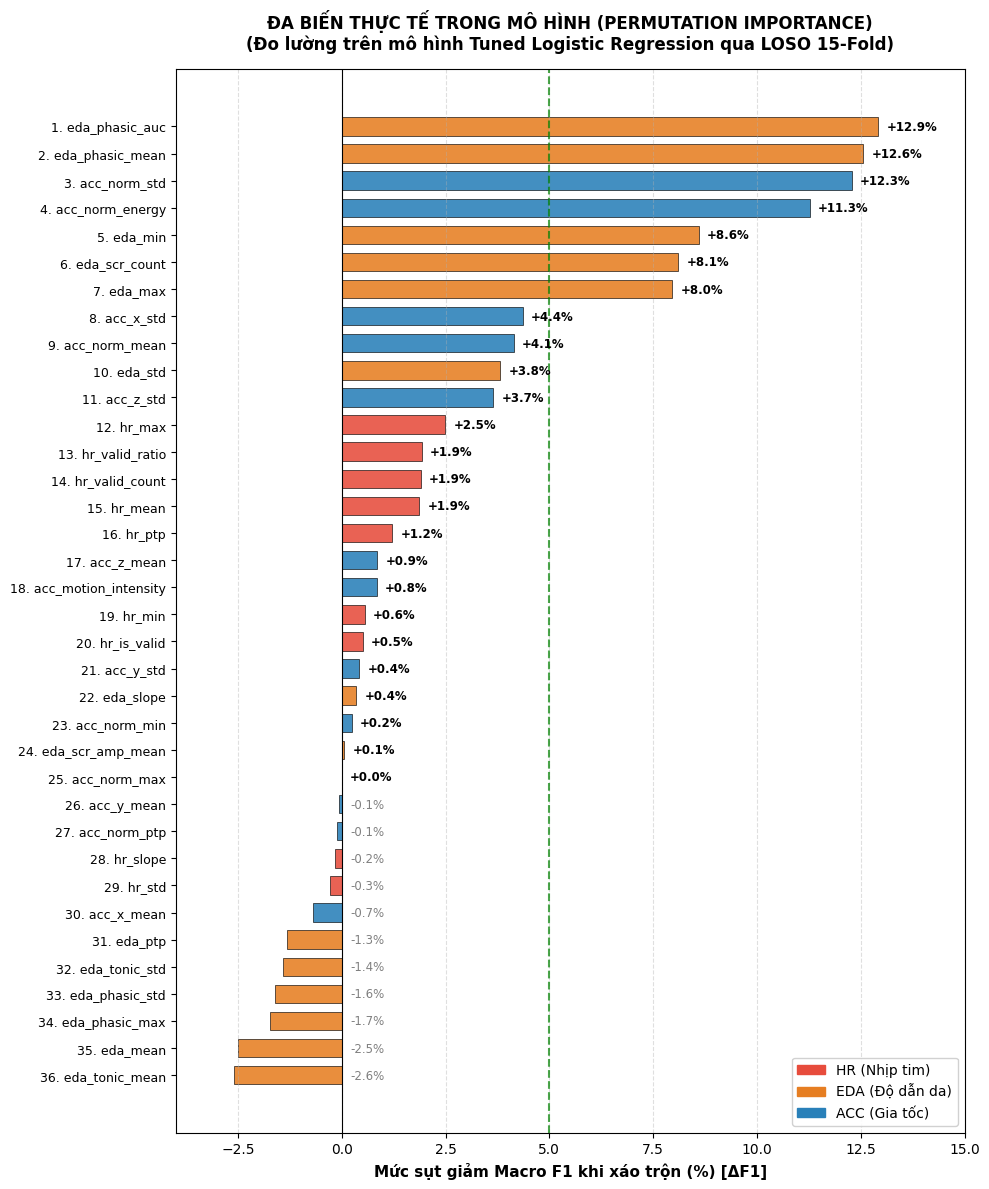

TOP 10 ĐẶC TRƯNG CÓ ĐÓNG GÓP THỰC TẾ LỚN NHẤT THEO PERMUTATION IMPORTANCE:


,Tên đặc trưng,Cảm biến,Permutation Imp (% F1 drop),Pearson |r| (Notebook 04)
Hạng Đa biến,,,,
1,eda_phasic_auc,EDA,12.925163,0.400803
2,eda_phasic_mean,EDA,12.553321,0.400803
3,acc_norm_std,ACC,12.284476,0.443668
4,acc_norm_energy,ACC,11.264721,0.221297
5,eda_min,EDA,8.594091,0.359216
6,eda_scr_count,EDA,8.107855,0.571174
7,eda_max,EDA,7.954763,0.381627
8,acc_x_std,ACC,4.363886,0.027068
9,acc_norm_mean,ACC,4.144804,0.127140


In [4]:
# 1. Nạp và sắp xếp bảng xếp hạng Permutation Feature Importance
df_perm = pd.DataFrame(three_rep['permutation_importance']).sort_values(by='perm_importance_pct', ascending=False).reset_index(drop=True)

# 2. Hàm định dạng màu sắc theo nhóm cảm biến
def get_sensor_color(name):
    if name.startswith('eda_'): return '#E67E22'  # Cam: EDA
    elif name.startswith('hr_'): return '#E74C3C'  # Đỏ: HR
    else: return '#2980B9'  # Xanh dương: ACC

# 3. Vẽ biểu đồ Permutation Feature Importance (36 đặc trưng)
fig, ax = plt.subplots(figsize=(10, 12))
y_pos = range(len(df_perm))
colors = [get_sensor_color(n) for n in df_perm['feature']]
bars = ax.barh(y_pos, df_perm['perm_importance_pct'], color=colors, height=0.68, alpha=0.88, edgecolor='black', linewidth=0.5)

ax.set_yticks(y_pos)
ax.set_yticklabels([f"{i+1:2d}. {n}" for i, n in enumerate(df_perm['feature'])], fontsize=9)
ax.invert_yaxis()

ax.axvline(0, color='black', linestyle='-', linewidth=0.8)
ax.axvline(5.0, color='green', linestyle='--', alpha=0.7, label='Đóng góp then chốt (+5% F1 drop)')

for bar in bars:
    w = bar.get_width()
    if w >= 0:
        ax.text(w + 0.2, bar.get_y() + bar.get_height()/2, f"{w:+.1f}%", va='center', ha='left', fontsize=8.5, fontweight='bold')
    else:
        ax.text(0.2, bar.get_y() + bar.get_height()/2, f"{w:+.1f}%", va='center', ha='left', fontsize=8.5, color='gray')

ax.set_xlim(-4, 15)
ax.set_xlabel('Mức sụt giảm Macro F1 khi xáo trộn (%) [ΔF1]', fontsize=11, fontweight='bold')
ax.set_title('ĐA BIẾN THỰC TẾ TRONG MÔ HÌNH (PERMUTATION IMPORTANCE)\n(Đo lường trên mô hình Tuned Logistic Regression qua LOSO 15-Fold)', 
             fontsize=12, fontweight='bold', pad=14)
ax.grid(axis='x', linestyle='--', alpha=0.4)

import matplotlib.patches as mpatches
legend_patches = [
    mpatches.Patch(color='#E74C3C', label='HR (Nhịp tim)'),
    mpatches.Patch(color='#E67E22', label='EDA (Độ dẫn da)'),
    mpatches.Patch(color='#2980B9', label='ACC (Gia tốc)')
]
ax.legend(handles=legend_patches, loc='lower right', framealpha=0.9, fontsize=10)

plt.tight_layout()
plt.show()

# 4. Hiển thị bảng đối chiếu Top 10 đặc trưng thực tế vs Pearson ở Notebook 04
print("TOP 10 ĐẶC TRƯNG CÓ ĐÓNG GÓP THỰC TẾ LỚN NHẤT THEO PERMUTATION IMPORTANCE:")
display_df = df_perm.head(10)[['Rank_Permutation', 'feature', 'sensor', 'perm_importance_pct', 'abs_pearson_r']].copy()
display_df.columns = ['Hạng Đa biến', 'Tên đặc trưng', 'Cảm biến', 'Permutation Imp (% F1 drop)', 'Pearson |r| (Notebook 04)']
display(display_df.set_index('Hạng Đa biến'))

## 4. Kiểm tra mô hình AI trên tập độc lập & Ma trận nhầm lẫn (LOSO 15-Fold)

- Sử dụng kiểm thử chéo **Leave-One-Subject-Out (LOSO 15-fold)** trên bộ **WESAD** (`3,040` cửa sổ từ `15` đối tượng): mỗi đối tượng kiểm thử hoàn toàn độc lập với mô hình được huấn luyện từ `14` đối tượng còn lại.
- Mô hình đánh giá: **Tuned Logistic Regression (`C=10.0`, `balanced`)** — đúng mô hình xuất xưởng lên ESP32-S3 (`wesad_lr_v1_folded`).

Chỉ số,Kết quả
Số mẫu kiểm thử,"3,040 cửa sổ độc lập (LOSO 15 đối tượng: 904 Stress / 2,136 Non-stress)"
Số mẫu đúng/sai,"2,757 đúng / 283 sai (Accuracy: 90.69%, Stress F1: 84.66%)"
Tỉ lệ cảnh báo sai,"7.49% (FPR = 160/2,136 mẫu Non-stress bị nhận nhầm Stress)"
Thời gian phản hồi,0.0021 ms/mẫu (Python) | < 0.01 ms suy luận C++ trên chu kỳ 10s
Nguồn nhãn đối chiếu,"Nhãn thực nghiệm chuẩn WESAD (Baseline, Amusement, Meditation vs TSST Stress)"


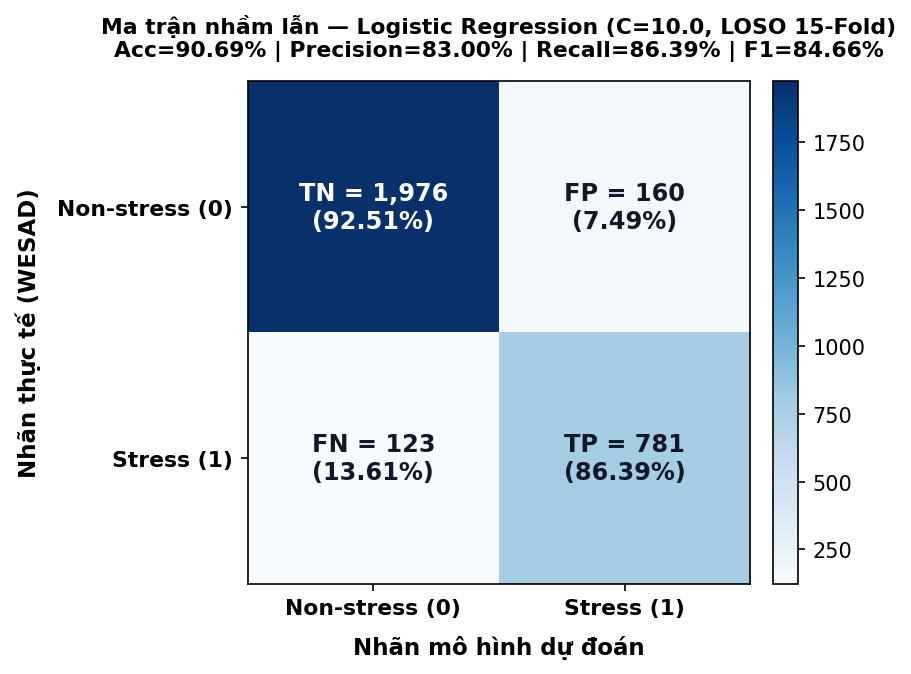

In [5]:
import time
from IPython.display import HTML, display
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, recall_score, precision_score

# 1. Tải dataset chuẩn WESAD (3,040 cửa sổ có nhãn thực nghiệm)
df_wesad = pd.read_csv(ROOT / "ai/data/processed/wesad/features-v1/dataset.csv")
meta_cols = {"subject_id", "window_start_ms", "window_end_ms", "source_label_code", "label"}
feat_cols = [c for c in df_wesad.columns if c not in meta_cols]
X_all = df_wesad[feat_cols].values
y_all = df_wesad["label"].values
groups = df_wesad["subject_id"].values

# 2. Đánh giá LOSO 15-fold độc lập theo từng đối tượng chưa từng thấy
y_true_list, y_pred_list = [], []
infer_times_ms = []

for subj in np.unique(groups):
    tr_mask = groups != subj
    te_mask = groups == subj
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(C=10.0, max_iter=2000, class_weight="balanced", random_state=42)),
    ])
    pipe.fit(X_all[tr_mask], y_all[tr_mask])
    t0 = time.perf_counter()
    preds = pipe.predict(X_all[te_mask])
    t1 = time.perf_counter()
    infer_times_ms.append((t1 - t0) * 1000.0 / len(X_all[te_mask]))
    y_true_list.append(y_all[te_mask])
    y_pred_list.append(preds)

y_true = np.concatenate(y_true_list)
y_pred = np.concatenate(y_pred_list)

cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()
total_n = int(len(y_true))
correct_n = int(tn + tp)
wrong_n = int(fp + fn)
fpr_pct = (fp / (tn + fp)) * 100.0
acc_pct = accuracy_score(y_true, y_pred) * 100.0
f1_stress_pct = f1_score(y_true, y_pred) * 100.0
prec_stress_pct = precision_score(y_true, y_pred) * 100.0
rec_stress_pct = recall_score(y_true, y_pred) * 100.0
avg_py_ms = float(np.mean(infer_times_ms))

# 3. Bảng kết quả kiểm tra mô hình AI (dạng 2 cột gọn để crop dán báo cáo)
df_report = pd.DataFrame([
    {"Chỉ số": "Số mẫu kiểm thử", "Kết quả": f"{total_n:,} cửa sổ độc lập (LOSO 15 đối tượng: {int((y_true==1).sum()):,} Stress / {int((y_true==0).sum()):,} Non-stress)"},
    {"Chỉ số": "Số mẫu đúng/sai", "Kết quả": f"{correct_n:,} đúng / {wrong_n:,} sai (Accuracy: {acc_pct:.2f}%, Stress F1: {f1_stress_pct:.2f}%)"},
    {"Chỉ số": "Tỉ lệ cảnh báo sai", "Kết quả": f"{fpr_pct:.2f}% (FPR = {fp}/{tn+fp:,} mẫu Non-stress bị nhận nhầm Stress)"},
    {"Chỉ số": "Thời gian phản hồi", "Kết quả": f"{avg_py_ms:.4f} ms/mẫu (Python) | < 0.01 ms suy luận C++ trên chu kỳ 10s"},
    {"Chỉ số": "Nguồn nhãn đối chiếu", "Kết quả": "Nhãn thực nghiệm chuẩn WESAD (Baseline, Amusement, Meditation vs TSST Stress)"},
])
display(HTML(df_report.to_html(index=False)))

# 4. Vẽ Ma trận nhầm lẫn (Confusion Matrix) nền trắng rõ nét để crop vào báo cáo
fig, ax = plt.subplots(figsize=(5.6, 4.6), dpi=150)
fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")
im = ax.imshow(cm, interpolation="nearest", cmap="Blues")

classes = ["Non-stress (0)", "Stress (1)"]
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(classes, fontsize=10.5, fontweight="bold")
ax.set_yticklabels(classes, fontsize=10.5, fontweight="bold")
ax.set_xlabel("Nhãn mô hình dự đoán", fontsize=11, fontweight="bold", labelpad=8)
ax.set_ylabel("Nhãn thực tế (WESAD)", fontsize=11, fontweight="bold", labelpad=8)
ax.set_title(
    f"Ma trận nhầm lẫn — Logistic Regression (C=10.0, LOSO 15-Fold)\nAcc={acc_pct:.2f}% | Precision={prec_stress_pct:.2f}% | Recall={rec_stress_pct:.2f}% | F1={f1_stress_pct:.2f}%",
    fontsize=10.5, fontweight="bold", pad=12
)

row_sums = cm.sum(axis=1, keepdims=True)
thresh = cm.max() / 2.0
labels_text = [["TN", "FP"], ["FN", "TP"]]
for i in range(2):
    for j in range(2):
        pct = cm[i, j] / row_sums[i, 0] * 100.0
        color = "white" if cm[i, j] > thresh else "#111827"
        ax.text(
            j, i,
            f"{labels_text[i][j]} = {cm[i, j]:,}\n({pct:.2f}%)",
            ha="center", va="center", color=color, fontsize=11.5, fontweight="bold"
        )

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()
